## 1. Setup

Load the tools. `tensorflow/keras` is the ML library that gives us the CNN building blocks.
`scikit-image` is what our old metric uses. Run this cell first — if an import fails, that
library isn't installed yet (`pip install ...`).

In [1]:
import os, numpy as np
import matplotlib.pyplot as plt

# our metric uses these:
from PIL import Image
from skimage import img_as_float, img_as_ubyte
from skimage.filters.rank import entropy
from skimage.morphology import disk

# the ML library
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
print("setup ready")

TensorFlow version: 2.21.0
setup ready


## 2. Download the segments from R2 (Cloudflare)

Instead of reading screenshots off your local disk, pull them straight from the R2 bucket. This
downloads every image in the bucket into a local folder once, then the rest of the notebook trains
from that folder — exactly the "download first, then train from the copy" flow from our diagram.

In [2]:
import sys
!{sys.executable} -m pip install boto3 --quiet

import os
import boto3
from botocore.config import Config

# ---- R2 (Cloudflare) connection ----
R2_ACCOUNT_ID = "7e641eadc881f6ff1bed3efd05a3fc2f"   # the account that holds the bucket (endpoint id, not secret)
ACCESS_KEY    = "10fdd6f3feac4c796d1b92bd77e74a0d"
SECRET_KEY    = "937acea7516a707e2e43587e81cae7371a26c4c4f9692801f66f89e2132e0926"
BUCKET        = "testwestfield"

s3 = boto3.client(
    "s3",
    endpoint_url=f"https://{R2_ACCOUNT_ID}.r2.cloudflarestorage.com",
    aws_access_key_id=ACCESS_KEY,
    aws_secret_access_key=SECRET_KEY,
    config=Config(signature_version="s3v4"),
)

# download every image in the bucket into a local folder
DATA_DIR = "r2_segments"
os.makedirs(DATA_DIR, exist_ok=True)

count = 0
paginator = s3.get_paginator("list_objects_v2")
for page in paginator.paginate(Bucket=BUCKET):
    for obj in page.get("Contents", []):
        key = obj["Key"]
        if key.lower().endswith((".png", ".jpg", ".tif")):
            s3.download_file(BUCKET, key, os.path.join(DATA_DIR, os.path.basename(key)))
            count += 1

print("downloaded", count, "segments from R2 bucket:", BUCKET)
print("DATA_DIR =", DATA_DIR)


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


downloaded 117 segments from R2 bucket: testwestfield
DATA_DIR = r2_segments


## 3. Get the segment images

`DATA_DIR` is already set by the R2 download cell above (the local copy of the bucket). The
pipeline names every segment `sector_roadname_segment.png` (e.g. `CC_1H_Burlington_Pike_000.png`).
We split each name into the **road** (everything before the trailing number) and the **segment
number**, then group the files **by road** so later we can rate each road on its own, the way
the router needs it.

In [3]:
# DATA_DIR comes from the R2 download cell above
# (to train from a local folder instead, set it here, e.g. DATA_DIR = "Westfield_segments")

# split a file name into its road and segment number
def parse_segment(filename):
    name = filename.rsplit(".", 1)[0]        # drop the .png
    road_key, seg = name.rsplit("_", 1)      # split off the trailing number
    return road_key, int(seg)

image_files = []
for filename in sorted(os.listdir(DATA_DIR)):
    if filename.lower().endswith((".png", ".jpg", ".tif")):
        image_files.append(filename)

# group the files by road
roads = {}
for filename in image_files:
    road_key, seg = parse_segment(filename)
    if road_key not in roads:
        roads[road_key] = []
    roads[road_key].append(filename)

print("found", len(image_files), "segment images across", len(roads), "road(s)")
for road_key in roads:
    print(" ", road_key, "->", len(roads[road_key]), "segments")

found 117 segment images across 1 road(s)
  D13D10_Westfield_Avenue -> 117 segments


## 4. Label the images using OUR metric

Our texture metric gives each image a 1–5. Those labels are the "right answers" the CNN will
learn from. We are **reusing our old code** here.

In [4]:
# --- our metric, reused as the labeler ---
CLEAN_TEXTURE = 1.1
WRECKED_TEXTURE = 2.8

def measure_roughness(path):
    image = Image.open(path).convert("L")

    # center-crop to the middle so we look at the road, not the edges
    width, height = image.size
    left = int(width * 0.1)
    top = int(height * 0.1)
    image = image.crop((left, top, width - left, height - top))

    pixels = np.array(image)
    roughness_map = entropy(pixels, disk(5))
    return roughness_map.mean()

def rate_image(path):
    roughness = measure_roughness(path)

    # how damaged is it, from 0 (clean) to 1 (wrecked)
    damage = (roughness - CLEAN_TEXTURE) / (WRECKED_TEXTURE - CLEAN_TEXTURE)
    if damage < 0:
        damage = 0
    if damage > 1:
        damage = 1

    level = round(5 - 4 * damage)
    return level

image_paths = []
labels = []
for filename in image_files:
    path = os.path.join(DATA_DIR, filename)
    image_paths.append(path)
    labels.append(rate_image(path))

print("labeled", len(labels), "images")
for level in [1, 2, 3, 4, 5]:
    print("level", level, ":", labels.count(level))

labeled 117 images
level 1 : 0
level 2 : 0
level 3 : 47
level 4 : 67
level 5 : 3


In [5]:
#debugging cell, only run to see the min,median,max of a road.
values = []
for path in image_paths:
    values.append(measure_roughness(path))

values.sort()
n = len(values)
print("min:   ", round(values[0], 2))
print("25th:  ", round(values[int(n*0.25)], 2))
print("median:", round(values[int(n*0.50)], 2))
print("75th:  ", round(values[int(n*0.75)], 2))
print("max:   ", round(values[-1], 2))

min:    1.23
25th:   1.51
median: 1.68
75th:   1.82
max:    2.16


## 5. Build the dataset (load images + split 80/20)

The CNN needs the images as same-size number grids, plus their labels. Then we split:
**80% to train on, 20% to test on** — the 20% is images the model never sees during training.
(With one small road this will overfit, but that's expected for the demo.)

In [5]:
from sklearn.model_selection import train_test_split

IMG_SIZE = 128

all_images = []
all_labels = []
for path, level in zip(image_paths, labels):
    image = Image.open(path).convert("L")
    width, height = image.size
    left = int(width * 0.1)
    top = int(height * 0.1)
    image = image.crop((left, top, width - left, height - top))
    image = image.resize((IMG_SIZE, IMG_SIZE))
    pixels = np.array(image) / 255.0
    all_images.append(pixels)
    all_labels.append(level - 1)

all_images = np.array(all_images)
all_images = all_images.reshape(len(all_images), IMG_SIZE, IMG_SIZE, 1)
all_labels = np.array(all_labels)

train_images, test_images, train_labels, test_labels = train_test_split(
    all_images, all_labels,
    test_size=0.2,
    random_state=1,
)

print("all images shape:", all_images.shape)
print("train:", len(train_images), "images | test:", len(test_images), "images")

all images shape: (117, 128, 128, 1)
train: 93 images | test: 24 images


## 6. Build the CNN

Conv layers find patterns (edges, cracks, textures); pooling shrinks things down; the final
`Dense(5, softmax)` outputs 5 numbers that add to 1 — the model's confidence for each road level.

This is a small custom CNN (simplest to understand). *Researching whether a pretrained model
like MobileNet would do better is the S2-10 task; we can swap this out later.*

In [6]:
model = models.Sequential()
model.add(layers.Input((IMG_SIZE, IMG_SIZE, 1)))

model.add(layers.Conv2D(16, 3, activation="relu"))
model.add(layers.MaxPooling2D())

model.add(layers.Conv2D(32, 3, activation="relu"))
model.add(layers.MaxPooling2D())

model.add(layers.Flatten())
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(5, activation="softmax"))   # 5 road levels

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,389 (7.05 MB)

 Trainable params: 1,848,389 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the CNN

This runs the guess → check → nudge loop automatically, over several passes (**epochs**).
Watch `accuracy` climb on the training data and `val_accuracy` on the held-out test data.
If training accuracy is high but val_accuracy is low → that's **overfitting** (memorizing).

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9892 - loss: 0.0703 - val_accuracy: 0.5417 - val_loss: 1.6681
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9892 - loss: 0.0457 - val_accuracy: 0.5417 - val_loss: 1.5341
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9892 - loss: 0.0727 - val_accuracy: 0.5417 - val_loss: 1.4101
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9892 - loss: 0.0516 - val_accuracy: 0.5417 - val_loss: 1.4514
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9892 - loss: 0.0534 - val_accuracy: 0.5417 - val_loss: 1.5998
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9892 - loss: 0.0393 - val_accuracy: 0.5833 - val_loss: 1.6951
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9892 - loss: 0.0635 - val_accuracy: 0.5833 - val_loss: 1.6247
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9892 - loss: 0.0438 - val_accuracy: 0.5417 - val_loss: 1.5476


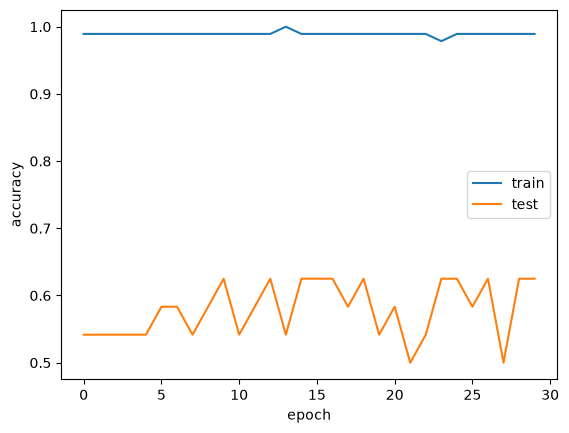

In [11]:
EPOCHS = 30

history = model.fit(
    train_images, train_labels,
    validation_data=(test_images, test_labels),
    epochs=EPOCHS,
)

plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="test")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

## 8. Evaluate: how good is it, really?

Test accuracy is measured on the **20% the model never trained on** that's the honest number,
and it will NOT be 100%. We also look at a few sample images with the model's prediction vs. the
true label, so we can *see* where it's right and wrong.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6250 - loss: 1.6706
TEST ACCURACY: 62.5 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


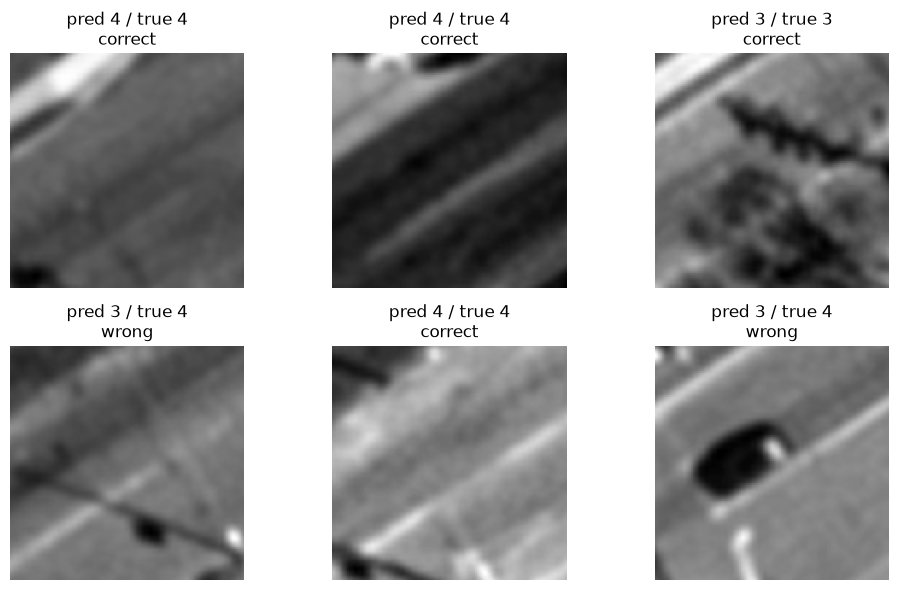

In [12]:
test_loss, test_accuracy = model.evaluate(test_images, test_labels)
print("TEST ACCURACY:", round(test_accuracy * 100, 1), "%")

predictions = model.predict(test_images)

plt.figure(figsize=(10, 6))
for i in range(6):
    guessed_level = np.argmax(predictions[i]) + 1
    true_level = test_labels[i] + 1

    if guessed_level == true_level:
        result = "correct"
    else:
        result = "wrong"

    plt.subplot(2, 3, i + 1)
    plt.imshow(test_images[i].reshape(IMG_SIZE, IMG_SIZE), cmap="gray")
    plt.title("pred " + str(guessed_level) + " / true " + str(true_level) + "\n" + result)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Save the trained model

The trained model is the whole point — save it to a file so it can be loaded later to classify
new roads without retraining. This file **is** the "learned brain." (Task 2 pushes this file to
GitHub so teammates can load it.)

In [13]:
model.save("road_cnn.keras")
print("saved -> road_cnn.keras")

# later, to reuse it without retraining:
# model = tf.keras.models.load_model("road_cnn.keras")

saved -> road_cnn.keras


## 10. Rate each road (what the router actually uses)

Point this at any folder of segment screenshots and it: loads every image the same way the model
was trained, **groups them by road**, runs the CNN, and averages each road's segment levels into a
single **1–5 road rating**. A road is only as good as it drives, so we also report the worst
segment. This `classify_folder()` function is the piece the rest of the system calls — the R2
download drops segments into a folder, and this turns them into per-road ratings.

In [14]:
def classify_folder(folder, model):
    # load + prep every image the SAME way the model was trained on
    roads = {}
    for filename in sorted(os.listdir(folder)):
        if not filename.lower().endswith((".png", ".jpg", ".tif")):
            continue
        road_key, seg = parse_segment(filename)

        image = Image.open(os.path.join(folder, filename)).convert("L")
        width, height = image.size
        left = int(width * 0.1)
        top = int(height * 0.1)
        image = image.crop((left, top, width - left, height - top))
        image = image.resize((IMG_SIZE, IMG_SIZE))
        pixels = np.array(image) / 255.0

        if road_key not in roads:
            roads[road_key] = []
        roads[road_key].append(pixels)

    # run the model per road and average the segment levels
    results = {}
    for road_key in roads:
        X = np.array(roads[road_key]).reshape(len(roads[road_key]), IMG_SIZE, IMG_SIZE, 1)
        levels = np.argmax(model.predict(X, verbose=0), axis=1) + 1
        results[road_key] = {
            "segments": len(levels),
            "average": round(float(levels.mean()), 1),
            "worst": int(levels.min()),
            "best": int(levels.max()),
        }
    return results


road_ratings = classify_folder(DATA_DIR, model)
for road_key in road_ratings:
    r = road_ratings[road_key]
    print(road_key, "-> avg", r["average"], "/5   (worst", r["worst"], ", best", r["best"],
          ",", r["segments"], "segments)")

D13D10_Westfield_Avenue -> avg 3.6 /5   (worst 3 , best 4 , 117 segments)
